<a href="https://colab.research.google.com/github/hilalozkaraman/perceptron_cat_vs_noncat/blob/main/Module16_Perceptron_Cat_vs_NonCat.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Module 16 Lab: NumPy ile Sıfırdan Perceptron — Cat vs Non-Cat Sınıflandırması


## Blok 1. Kütüphanelerin kurulumu ve içe aktarılması


In [1]:
import importlib.util, subprocess, sys
required = {'numpy':'numpy', 'pandas':'pandas', 'h5py':'h5py',
            'matplotlib':'matplotlib', 'seaborn':'seaborn',
            'PIL':'pillow', 'scipy':'scipy', 'sklearn':'scikit-learn'}
missing = [pip_name for module, pip_name in required.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])

import os, time, json, pickle, shutil, urllib.request, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns
import h5py
from PIL import Image, ImageOps
from scipy import ndimage
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, roc_curve,
                             roc_auc_score, precision_recall_curve, average_precision_score,
                             balanced_accuracy_score)
print('numpy     :', np.__version__)
print('pandas    :', pd.__version__)
print('h5py      :', h5py.__version__)
print('Pillow    :', Image.__version__)

numpy     : 2.4.6
pandas    : 2.2.3
h5py      : 3.14.0
Pillow    : 11.3.0


## Blok 2. Deney ayarları ve grafik stili

In [2]:
FAST_MODE       = False       # True: hizli prova; False: tam deney
RANDOM_STATE    = 42
VAL_SIZE        = 0.20        # Sadece orijinal egitim verisinden dogrulama ayrilir
LEARNING_RATE   = 0.002
MIN_DELTA       = 1e-7
PRINT_EVERY     = 10 if FAST_MODE else 25
THRESHOLD       = 0.50

# --- Overfitting'e karsi eklenen ayarlar (model hala tek sigmoid noron + MSE + SGD) ---
DOWNSAMPLE      = 4           # 64x64 -> 16x16 ortalama pooling (12288 -> 768 ozellik); 1 = kapali
AUGMENT         = True        # Sadece egitim verisi: cevirme + kucuk donme (x4 veri)
AUG_ANGLE       = 10          # Rastgele donme araligi (derece)
L2_GRID         = [0.0, 0.003, 0.01, 0.03, 0.1, 0.3]   # CV ile taranacak L2 (weight decay) katsayilari
CV_FOLDS        = 5
CV_EPOCHS       = 30 if FAST_MODE else 150
LR_DECAY        = 0.02        # lr_t = lr / (1 + LR_DECAY * (epoch-1))
OUT_DIR         = Path('outputs_module16_v5')
OUT_DIR.mkdir(exist_ok=True)

# Kaynak notebooka benzer sade ve belirgin grafik dili
C_TR, C_VA, C_TE = '#2a78d6', '#eb6834', '#279877'
C_INK, C_MUTED, C_GRID, C_AXIS, C_SURF = '#0b0b0b', '#898781', '#e1e0d9', '#c3c2b7', '#fcfcfb'
plt.rcParams.update({
    'figure.facecolor': C_SURF, 'axes.facecolor': C_SURF, 'savefig.facecolor': C_SURF,
    'axes.edgecolor': C_AXIS, 'axes.labelcolor': C_INK, 'text.color': C_INK,
    'xtick.color': C_MUTED, 'ytick.color': C_MUTED,
    'axes.grid': True, 'grid.color': C_GRID, 'grid.linewidth': 0.8,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.axisbelow': True,
    'font.family': 'sans-serif', 'font.size': 11, 'legend.frameon': False,
    'lines.linewidth': 2, 'figure.dpi': 110,
})

def save_fig(name):
    path = OUT_DIR / name
    plt.savefig(path, bbox_inches='tight', dpi=160)
    print('Grafik kaydedildi:', path)

print('Ayarlar:', dict(FAST_MODE=FAST_MODE,
                      LEARNING_RATE=LEARNING_RATE, VAL_SIZE=VAL_SIZE,
                      RANDOM_STATE=RANDOM_STATE,
                      DOWNSAMPLE=DOWNSAMPLE, AUGMENT=AUGMENT, L2_GRID=L2_GRID))

Ayarlar: {'FAST_MODE': False, 'LEARNING_RATE': 0.002, 'VAL_SIZE': 0.2, 'RANDOM_STATE': 42, 'DOWNSAMPLE': 4, 'AUGMENT': True, 'L2_GRID': [0.0, 0.003, 0.01, 0.03, 0.1, 0.3]}


## Blok 3. Cat vs Non-Cat veri setini bulma / indirme

In [3]:
DATASET_SLUG = 'muhammeddalkran/catvnoncat'
TRAIN_NAME = 'train_catvnoncat.h5'
TEST_NAME = 'test_catvnoncat.h5'

def is_data_pair(folder):
    folder = Path(folder)
    return (folder / TRAIN_NAME).is_file() and (folder / TEST_NAME).is_file() \
        and h5py.is_hdf5(folder / TRAIN_NAME) and h5py.is_hdf5(folder / TEST_NAME)

def find_existing_dataset(extra=None):
    roots = [Path('.'), Path('data'), Path('datasets'), Path('catvnoncat'),
             Path('/kaggle/input/catvnoncat'), Path('/content/catvnoncat'),
             Path('/content/data'), Path('/content/datasets')]
    if extra is not None:
        roots.insert(0, Path(extra))
    for root in roots:
        if is_data_pair(root):
            return root
        if root.is_dir() and root != Path('.'):
            for p in root.glob('*/'):
                if is_data_pair(p):
                    return p
    return None

errors = []
DATA_DIR = find_existing_dataset()
if DATA_DIR is None:
    try:
        if importlib.util.find_spec('kagglehub') is None:
            subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'kagglehub'])
        import kagglehub
        download_folder = Path(kagglehub.dataset_download(DATASET_SLUG))
        DATA_DIR = find_existing_dataset(download_folder)
        print('KaggleHub indirilen klasor:', download_folder)
    except Exception as e:
        errors.append('KaggleHub: ' + repr(e))

if DATA_DIR is None:
    raise FileNotFoundError(
        'Gercek Cat vs Non-Cat verisi bulunamadi. Kaggle sayfasindan '
        'train_catvnoncat.h5 ve test_catvnoncat.h5 dosyalarini indirip '
        'notebook ile ayni klasore veya data/ icine koyun.\n' + '\n'.join(errors))
print('Veri seti klasoru:', Path(DATA_DIR).resolve())

Veri seti klasoru: /kaggle/input/catvnoncat/catvnoncat


## Blok 4. H5 dosyalarını okuma ve veriyi doğrulama

Görüntülerin biçimi `(örnek, yükseklik, genişlik, 3)`; sınıflar `0=kedi değil` ve `1=kedi`. H5 dosyalarını `with` ile güvenli biçimde kapatıyoruz.

In [4]:
def load_cat_dataset(data_dir):
    with h5py.File(Path(data_dir) / TRAIN_NAME, 'r') as train_file:
        X_train_raw = np.array(train_file['train_set_x'][:], dtype=np.uint8)
        y_train_raw = np.array(train_file['train_set_y'][:], dtype=np.int64).ravel()
        print('Train H5 anahtarlar:', list(train_file.keys()))
    with h5py.File(Path(data_dir) / TEST_NAME, 'r') as test_file:
        X_test_raw = np.array(test_file['test_set_x'][:], dtype=np.uint8)
        y_test_raw = np.array(test_file['test_set_y'][:], dtype=np.int64).ravel()
        class_names = ([s.decode('utf-8') if isinstance(s, bytes) else str(s)
                        for s in test_file['list_classes'][:]]
                       if 'list_classes' in test_file else ['non-cat', 'cat'])
        print('Test  H5 anahtarlar:', list(test_file.keys()))
    assert X_train_raw.ndim == X_test_raw.ndim == 4
    assert X_train_raw.shape[1:] == X_test_raw.shape[1:]
    assert X_train_raw.shape[-1] == 3
    assert len(X_train_raw) == len(y_train_raw) and len(X_test_raw) == len(y_test_raw)
    assert set(np.unique(y_train_raw)).issubset({0,1})
    assert set(np.unique(y_test_raw)).issubset({0,1})
    return X_train_raw, y_train_raw, X_test_raw, y_test_raw, class_names

X_train_raw, y_train_raw, X_test_raw, y_test_raw, class_names = load_cat_dataset(DATA_DIR)
IMG_H, IMG_W, IMG_C = X_train_raw.shape[1:]
N_FEATURES = IMG_H * IMG_W * IMG_C
print('Train (ham):', X_train_raw.shape, ' | Y:', y_train_raw.shape)
print('Test  (ham):', X_test_raw.shape, ' | Y:', y_test_raw.shape)
print('Gorsel boyutu:', (IMG_H, IMG_W, IMG_C), '| Piksel sayisi:', N_FEATURES)
print('Siniflar:', class_names, '| 0 = kedi degil, 1 = kedi')

Train H5 anahtarlar: ['list_classes', 'train_set_x', 'train_set_y']
Test  H5 anahtarlar: ['list_classes', 'test_set_x', 'test_set_y']
Train (ham): (209, 64, 64, 3)  | Y: (209,)
Test  (ham): (50, 64, 64, 3)  | Y: (50,)
Gorsel boyutu: (64, 64, 3) | Piksel sayisi: 12288
Siniflar: ['non-cat', 'cat'] | 0 = kedi degil, 1 = kedi


## Blok 5. Veriyi tanıma: örnek görseller ve sınıf dağılımı

Rastgele örnekleri ve **eğitim/test sınıf dağılımlarını** çiziyoruz; küçük veri setlerinde dengesizlik değerlendirmeyi etkileyebilir.

Grafik kaydedildi: outputs_module16_v5/01_ornek_gorseller.png


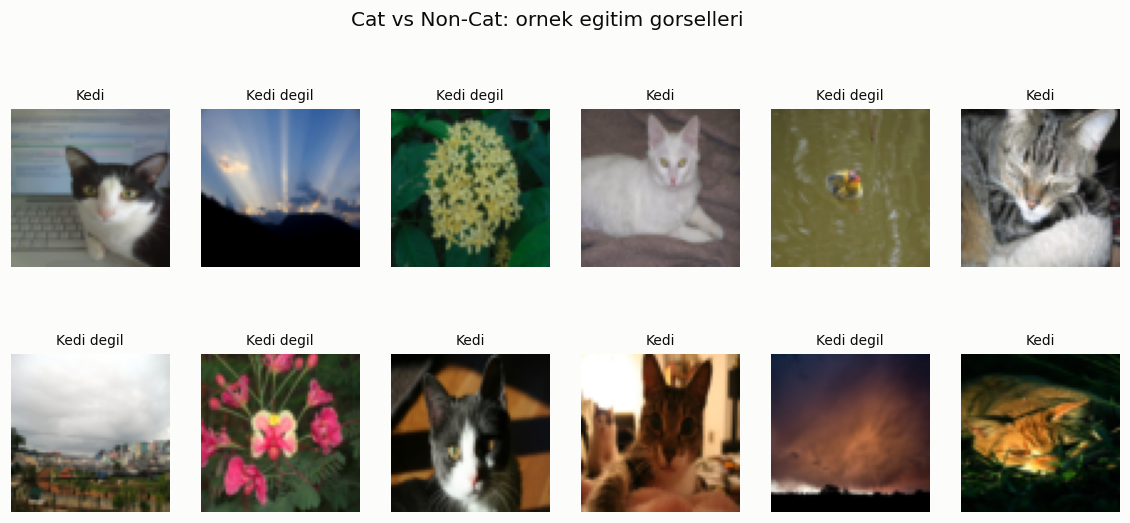

Grafik kaydedildi: outputs_module16_v5/02_sinif_dagilimi.png


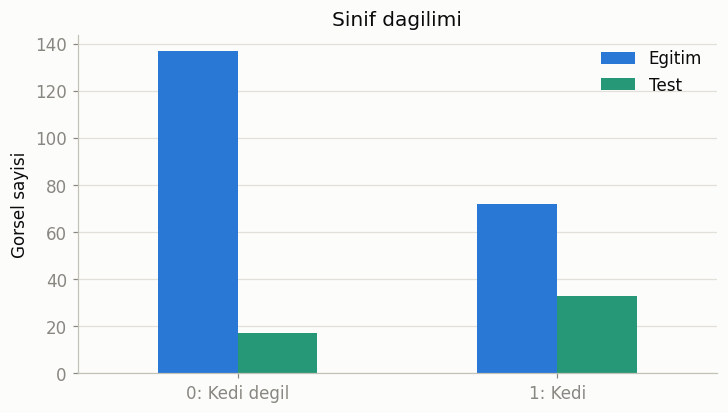

               Egitim  Test
0: Kedi degil     137    17
1: Kedi            72    33


In [5]:
fig, axes = plt.subplots(2, 6, figsize=(13, 5.3))
rng = np.random.default_rng(RANDOM_STATE)
choices = rng.choice(len(X_train_raw), size=min(12, len(X_train_raw)), replace=False)
for ax in axes.ravel():
    ax.axis('off')
for ax, idx in zip(axes.ravel(), choices):
    ax.imshow(X_train_raw[idx])
    ax.set_title('Kedi' if y_train_raw[idx] == 1 else 'Kedi degil', fontsize=9)
fig.suptitle('Cat vs Non-Cat: ornek egitim gorselleri', y=1.01)
save_fig('01_ornek_gorseller.png'); plt.show()

counts = pd.DataFrame({'Egitim': np.bincount(y_train_raw, minlength=2),
                       'Test': np.bincount(y_test_raw, minlength=2)}, index=['0: Kedi degil','1: Kedi'])
ax = counts.plot.bar(figsize=(7.5, 4), color=[C_TR, C_TE], rot=0)
ax.set_ylabel('Gorsel sayisi'); ax.set_title('Sinif dagilimi')
ax.grid(axis='x', visible=False)
save_fig('02_sinif_dagilimi.png'); plt.show()
print(counts.to_string())
counts.to_csv(OUT_DIR / 'sinif_dagilimi.csv')

## Blok 6. Eğitim / doğrulama / test ayrımı

**Veri sızıntısını önleme:** Orijinal test H5 dosyası aynen saklanır; modelin eğitimi ve erken durdurması için yalnızca orijinal eğitim dosyası bölünür.

In [6]:
train_indices, val_indices = train_test_split(
    np.arange(len(y_train_raw)), test_size=VAL_SIZE, random_state=RANDOM_STATE,
    stratify=y_train_raw)
X_fit_raw, X_val_raw = X_train_raw[train_indices], X_train_raw[val_indices]
y_fit, y_val = y_train_raw[train_indices], y_train_raw[val_indices]

# CV yalnizca egitim bolumundeki orijinal goruntulerde calisir.
# Bu kopyalar veri artirimindan etkilenmez.
X_cv_raw = X_fit_raw.copy()
y_cv = y_fit.copy()
y_test = y_test_raw.copy()
print('Model egitimi  :', len(y_fit), 'ornek')
print('Dogrulama     :', len(y_val), 'ornek')
print('Bagimsiz test :', len(y_test), 'ornek')
assert len(set(train_indices) & set(val_indices)) == 0
assert len(X_cv_raw) + len(X_val_raw) == len(X_train_raw)
print('CV kaynak goruntuleri:', len(X_cv_raw), '| Bagimsiz dogrulama:', len(X_val_raw))

Model egitimi  : 167 ornek
Dogrulama     : 42 ornek
Bagimsiz test : 50 ornek
CV kaynak goruntuleri: 167 | Bagimsiz dogrulama: 42


## Blok 7. Veri artırımı, küçültme, düzleştirme ve merkezleme

Ödevdeki model (tek nöron, sigmoid, MSE, SGD) **değişmiyor**; yalnızca girdi hazırlığı iyileştiriliyor:

1. **Veri artırımı (sadece eğitim bölümü):** orijinal + yatay çevrilmiş + küçük açıyla döndürülmüş görüntüler (×4). Doğrulama ve test verisine **dokunulmaz**.
2. **Küçültme:** `64×64×3` görüntü, `4×4` ortalama pooling ile `16×16×3`'e indirilir (12.288 → 768 parametre). Çok az örnek / çok fazla parametre oranı aşırı öğrenmenin ana nedenidir.
3. **Normalizasyon + merkezleme:** `[0,255] → [0,1]`, sonra **eğitim** ortalaması her özellikten çıkarılır.

Her `(h, w, 3)` görüntü bir **özellik sütunu** olur: `X: (özellik, m)`.


In [7]:
assert IMG_H % DOWNSAMPLE == 0 and IMG_W % DOWNSAMPLE == 0
FEAT_H, FEAT_W = IMG_H // DOWNSAMPLE, IMG_W // DOWNSAMPLE
N_FEATURES = FEAT_H * FEAT_W * IMG_C

def augment_images(images, labels, seed=42, angle=AUG_ANGLE):
    # Orijinal + yatay cevirme + rastgele kucuk donme + donmus cevirme  (x4)
    rng = np.random.default_rng(seed)
    flipped = images[:, :, ::-1, :]
    def rotate(batch):
        out = np.empty_like(batch)
        for i, im in enumerate(batch):
            out[i] = ndimage.rotate(im, rng.uniform(-angle, angle), axes=(0, 1),
                                    reshape=False, order=1, mode='reflect')
        return out
    imgs = np.concatenate([images, flipped, rotate(images), rotate(flipped)])
    return imgs, np.concatenate([labels] * 4)

def extract_features(images):
    # [0,255] -> [0,1], DOWNSAMPLE x DOWNSAMPLE ortalama pooling, duzlestirme: (ozellik, ornek)
    x = images.astype(np.float64) / 255.0
    n, h, w, c = x.shape
    f = DOWNSAMPLE
    if f > 1:
        x = x.reshape(n, h // f, f, w // f, f, c).mean(axis=(2, 4))
    return x.reshape(n, -1).T

N_FIT_ORIG = len(y_fit)
if AUGMENT:
    X_fit_raw, y_fit = augment_images(X_fit_raw, y_fit, RANDOM_STATE)
    print(f'Veri artirimi: {N_FIT_ORIG} -> {len(y_fit)} egitim ornegi')

X_fit_f = extract_features(X_fit_raw)
MU = X_fit_f.mean(axis=1, keepdims=True)          # sadece egitim ortalamasi (sizinti yok)

def preprocess_images(images):
    return extract_features(images) - MU

X_fit  = X_fit_f - MU
X_val  = preprocess_images(X_val_raw)
X_test = preprocess_images(X_test_raw)
Y_fit  = y_fit.reshape(1, -1).astype(np.float64)
Y_val  = y_val.reshape(1, -1).astype(np.float64)
Y_test = y_test.reshape(1, -1).astype(np.float64)

assert X_fit.shape == (N_FEATURES, len(y_fit))
assert X_val.shape[0] == X_test.shape[0] == N_FEATURES
print('X_fit :', X_fit.shape, '| Y_fit :', Y_fit.shape)
print('X_val :', X_val.shape, '| Y_val :', Y_val.shape)
print('X_test:', X_test.shape, '| Y_test:', Y_test.shape)
print('Ozellik sayisi:', N_FEATURES, f'({FEAT_H}x{FEAT_W}x{IMG_C})',
      '| egitim ortalamasi sonrasi ort:', round(float(X_fit.mean()), 6))


Veri artirimi: 167 -> 668 egitim ornegi
X_fit : (768, 668) | Y_fit : (1, 668)
X_val : (768, 42) | Y_val : (1, 42)
X_test: (768, 50) | Y_test: (1, 50)
Ozellik sayisi: 768 (16x16x3) | egitim ortalamasi sonrasi ort: -0.0


## Matematiksel temel: tek nöronlu Perceptron

Bu çalışmadaki Perceptron, **tek sigmoid çıktılı doğrusal bir sınıflandırıcıdır**; gerçek bir gizli katmanı yoktur. PDF'deki “one hidden artificial neuron” ifadesini, hesaplanan tek yapay nöron olarak uyguluyoruz.

## Blok 8. Ağırlık ve bias parametrelerinin başlatılması

`w` vektörünün her elemanı bir piksel-kanala karşılık gelir. `b` tek bir bias değeridir. Başlangıç tekrar üretilebilir.

In [8]:
def initialize_parameters(n_features, seed=42):
    rng = np.random.default_rng(seed)
    w = rng.normal(loc=0.0, scale=0.001, size=(n_features, 1))
    b = 0.0
    assert w.shape == (n_features, 1)
    return w, b

w0, b0 = initialize_parameters(N_FEATURES, RANDOM_STATE)
print('w boyutu:', w0.shape, '| b:', b0)
print('Ortalama agirlik:', float(w0.mean()), '| std:', float(w0.std()))

w boyutu: (768, 1) | b: 0.0
Ortalama agirlik: -3.641071049673891e-05 | std: 0.0009850748438304851


## Blok 9. Sigmoid aktivasyonunun sıfırdan yazılması

`1/(1+exp(-z))` fonksiyonunu büyük mutlak değerli sayılarda taşma yaşamayacak şekilde NumPy ile uyguluyoruz.

Grafik kaydedildi: outputs_module16_v5/03_sigmoid.png


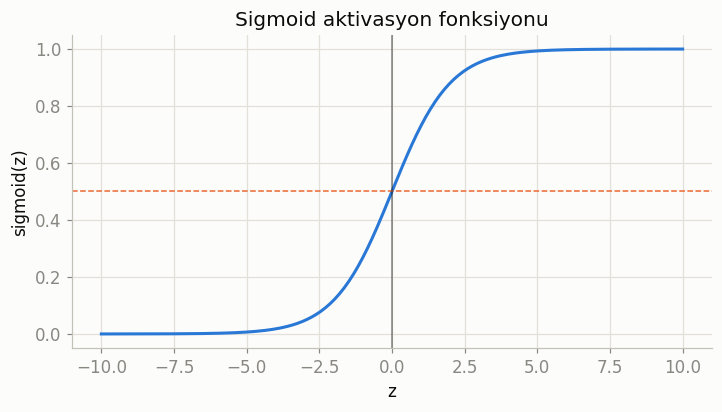

In [9]:
def sigmoid(z):
    z = np.asarray(z, dtype=np.float64)
    result = np.empty_like(z, dtype=np.float64)
    pos = z >= 0
    result[pos] = 1.0 / (1.0 + np.exp(-z[pos]))
    exp_z = np.exp(z[~pos])
    result[~pos] = exp_z / (1.0 + exp_z)
    return result

z_grid = np.linspace(-10, 10, 250)
fig, ax = plt.subplots(figsize=(7.5, 3.7))
ax.plot(z_grid, sigmoid(z_grid), color=C_TR)
ax.axhline(0.5, color=C_VA, ls='--', lw=1)
ax.axvline(0.0, color=C_INK, lw=1, alpha=0.5)
ax.set_xlabel('z'); ax.set_ylabel('sigmoid(z)')
ax.set_title('Sigmoid aktivasyon fonksiyonu')
save_fig('03_sigmoid.png'); plt.show()
assert np.isclose(float(sigmoid(np.array(0.0))), 0.5)

## Blok 10. İleri yayılım (forward) ve MSE kaybı

Ağırlıklı toplam, sigmoid ve ortalama karesel hata hesaplamalarını **ayrı fonksiyonlara** ayırıyoruz.

In [10]:
def forward_propagation(w, b, X):
    assert X.shape[0] == w.shape[0]
    Z = w.T @ X + b
    A = sigmoid(Z)
    return A

def compute_mse(A, Y):
    assert A.shape == Y.shape
    return float(np.mean(np.square(A - Y)))

A0 = forward_propagation(w0, b0, X_fit)
initial_loss = compute_mse(A0, Y_fit)
print('Ilk tahminler:', np.round(A0[0,:5], 4))
print('Baslangic MSE:', round(initial_loss, 6))
assert A0.shape == Y_fit.shape

Ilk tahminler: [0.5004 0.5009 0.5004 0.5015 0.5004]
Baslangic MSE: 0.250041


## Blok 11. Geri yayılım (backpropagation) — gradyanlar

MSE ve sigmoid türevleri **analitik olarak** uygulanıyor. Bu fonksiyon istenirse birden fazla örnek üzerinde ortalama gradyan hesabında da kullanılabilir.

In [11]:
def backward_propagation(w, b, X, Y):
    m = X.shape[1]
    A = forward_propagation(w, b, X)
    dZ = (2.0 / m) * (A - Y) * A * (1.0 - A)
    dw = X @ dZ.T
    db = float(np.sum(dZ))
    assert dw.shape == w.shape
    return dw, db

dw0, db0 = backward_propagation(w0, b0, X_fit[:, :3], Y_fit[:, :3])
print('dw:', dw0.shape, '| db:', round(db0, 8))

dw: (768, 1) | db: -0.08304956


## Blok 12. Sayısal gradyan testi (gradient checking)

Türevin doğruluğunu sonlu farkla doğruluyoruz. Bu kontrol, yanlış SGD güncellemesiyle tüm eğitimin bozulmasını önler.

In [12]:
x_chk, y_chk = X_fit[:14, :4], Y_fit[:, :4]
w_chk, b_chk = initialize_parameters(x_chk.shape[0], RANDOM_STATE)
dw_chk, db_chk = backward_propagation(w_chk, b_chk, x_chk, y_chk)
eps = 1e-5
check_rows = []
for j in [0, 3, 7, 13]:
    wp, wm = w_chk.copy(), w_chk.copy()
    wp[j, 0] += eps
    wm[j, 0] -= eps
    numeric = (compute_mse(forward_propagation(wp, b_chk, x_chk), y_chk) -
               compute_mse(forward_propagation(wm, b_chk, x_chk), y_chk)) / (2*eps)
    check_rows.append([f'w[{j}]', float(dw_chk[j,0]), float(numeric), abs(float(dw_chk[j,0])-numeric)])
numeric_b = (compute_mse(forward_propagation(w_chk, b_chk+eps, x_chk), y_chk) -
             compute_mse(forward_propagation(w_chk, b_chk-eps, x_chk), y_chk)) / (2*eps)
check_rows.append(['bias', db_chk, float(numeric_b), abs(db_chk-numeric_b)])
grad_table = pd.DataFrame(check_rows, columns=['Parametre','Analitik','Sayisal','Mutlak fark'])
print(grad_table.to_string(index=False))
assert grad_table['Mutlak fark'].max() < 1e-6, 'Gradient check basarisiz!'
print('Gradyanlar dogrulandi.')

Parametre  Analitik   Sayisal  Mutlak fark
     w[0]  0.008230  0.008230 5.801991e-13
     w[3]  0.004585  0.004585 1.435406e-12
     w[7] -0.011931 -0.011931 2.270415e-12
    w[13] -0.005910 -0.005910 3.828656e-13
     bias  0.000072  0.000072 1.105199e-12
Gradyanlar dogrulandi.


## Blok 13. Stochastic Gradient Descent (tek örneklik güncelleme) + L2

Mini-batch veya full-batch değil: **her SGD adımında sadece bir `(x_i, y_i)` çifti** kullanılır.

**L2 (weight decay):** kayıp hâlâ **MSE**'dir; yalnızca aşırı büyük ağırlıkları cezalandıran `(λ/2)·‖w‖²` terimi eklenir:

`w ← w − η · (∂MSE/∂w + λ·w)`  (bias cezalandırılmaz, `λ = 0` orijinal ödev güncellemesidir)


In [13]:
def sgd_update(w, b, x_i, y_i, learning_rate, l2_lambda=0.0):
    # x_i:(n_features,1), y_i:(1,1). Analitik MSE gradyani + L2 (weight decay).
    dw, db = backward_propagation(w, b, x_i, y_i)
    w = w - learning_rate * (dw + l2_lambda * w)
    b = b - learning_rate * db
    return w, float(b)

w_demo, b_demo = sgd_update(w0.copy(), b0, X_fit[:, :1], Y_fit[:, :1], LEARNING_RATE)
print('Tek SGD adimi sonrasi ||delta_w||:', np.linalg.norm(w_demo-w0))
print('Bias degisimi:', b_demo-b0)
assert np.linalg.norm(w_demo-w0) > 0


Tek SGD adimi sonrasi ||delta_w||: 0.002358562859088086
Bias degisimi: 0.0004996176354584903


## Blok 14. Tahmin olasılıkları ve ikili sınıf kararları

Sigmoid çıktısı `P(kedi)` olarak yorumlanır. Eşik `0.5` veya ihtiyaç halinde farklı bir değer olabilir.

In [14]:
def predict_proba(w, b, X):
    return forward_propagation(w, b, X).reshape(-1)

def predict(w, b, X, threshold=0.5):
    return (predict_proba(w, b, X) >= threshold).astype(np.int64)

print('Ornek olasiliklar:', np.round(predict_proba(w0,b0,X_fit[:,:5]), 3))
print('Ornek siniflar   :', predict(w0,b0,X_fit[:,:5]))

Ornek olasiliklar: [0.5   0.501 0.5   0.501 0.5  ]
Ornek siniflar   : [1 1 1 1 1]


## Blok 15. Ana `model()` fonksiyonu: SGD ile uçtan uca eğitim

Başlangıç + forward + MSE + backprop + `sgd_update` fonksiyonları tek bir `model()` çatısı altında birleşiyor. Her epoch sonunda eğitim ve doğrulama MSE'si ile doğruluğu kaydedilir.

`model()` ayrıca **L2 katsayısı** (`l2_lambda`) ve **öğrenme oranı azaltma** (`lr_decay`) parametrelerini alır. Doğrulama kümesi yalnızca 42 örnek olduğundan epoch sayısı ve λ, bir sonraki blokta **5-katlı çapraz doğrulama** ile seçilir; son model seçilen epoch sayısı kadar eğitilir. Fonksiyonda erken durdurma seçeneği de bulunur, ancak bu deneyde kullanılmamıştır.

In [15]:
def model(X_train, Y_train, X_valid, Y_valid,
          num_epochs=300, learning_rate=0.0007,
          patience=65, min_delta=1e-7, seed=42, verbose_every=25,
          l2_lambda=0.0, lr_decay=0.0, restore_best=True):
    assert X_train.shape[1] == Y_train.shape[1]
    assert X_valid.shape[1] == Y_valid.shape[1]
    rng = np.random.default_rng(seed)
    w, b = initialize_parameters(X_train.shape[0], seed)
    history = {'epoch': [], 'train_mse': [], 'val_mse': [],
               'train_accuracy': [], 'val_accuracy': []}
    best_loss, best_epoch = float('inf'), 0
    best_w, best_b, stale = w.copy(), float(b), 0
    started = time.perf_counter()

    for epoch in range(1, num_epochs + 1):
        indices = rng.permutation(X_train.shape[1])
        lr_t = learning_rate / (1.0 + lr_decay * (epoch - 1))
        for idx in indices:
            xi = X_train[:, idx:idx+1]  # 1 ornek = 1 SGD adimi
            yi = Y_train[:, idx:idx+1]
            w, b = sgd_update(w, b, xi, yi, lr_t, l2_lambda)

        train_p = predict_proba(w, b, X_train)
        val_p = predict_proba(w, b, X_valid)
        train_mse = compute_mse(train_p.reshape(1,-1), Y_train)
        val_mse = compute_mse(val_p.reshape(1,-1), Y_valid)
        train_acc = accuracy_score(Y_train.ravel(), (train_p >= THRESHOLD))
        val_acc = accuracy_score(Y_valid.ravel(), (val_p >= THRESHOLD))

        history['epoch'].append(epoch)
        history['train_mse'].append(train_mse)
        history['val_mse'].append(val_mse)
        history['train_accuracy'].append(float(train_acc))
        history['val_accuracy'].append(float(val_acc))

        if val_mse < best_loss - min_delta:
            best_loss, best_epoch = val_mse, epoch
            best_w, best_b, stale = w.copy(), float(b), 0
        else:
            stale += 1
        if verbose_every and (epoch == 1 or epoch % verbose_every == 0 or epoch == num_epochs):
            print(f'Epoch {epoch:3d}/{num_epochs} | train MSE {train_mse:.5f} '
                  f'| val MSE {val_mse:.5f} | train acc {train_acc:.3f} '
                  f'| val acc {val_acc:.3f}')
        if stale >= patience:
            print(f'Erken durdurma: epoch {epoch}; en iyi epoch {best_epoch}')
            break

    if not restore_best:   # CV ile secilen epoch'ta dur, son agirliklari kullan
        best_w, best_b, best_epoch, best_loss = w.copy(), float(b), epoch, val_mse

    return {'w': best_w, 'b': best_b, 'history': pd.DataFrame(history),
            'best_epoch': best_epoch, 'best_val_mse': best_loss,
            'train_seconds': time.perf_counter() - started,
            'hyperparameters': {'num_epochs': num_epochs, 'learning_rate': learning_rate, 'l2_lambda': l2_lambda, 'lr_decay': lr_decay,
                                'patience': patience, 'seed': seed}}


## Blok 16. L2 ve epoch secimi — YALNIZCA egitim verisiyle 5-Fold CV

**Kritik duzeltme:** CV, orijinal 209 goruntunun tamami uzerinde degil, ilk ayrilan egitim kismi (`X_cv_raw`, yaklasik 167 goruntu) uzerinde yapilir. Boylece `X_val_raw` (yaklasik 42 goruntu) CV'ye hic girmez ve ayri bir dogrulama kumesi olarak kalir.

Her kat icin veri artirimi sadece katin egitim goruntulerine uygulanir. **Merkezleme ortalamasi da katin kendi egitim goruntulerinden hesaplanir**; baska katin dogrulama goruntulerinin ortalamasi kullanilmaz. Test verisi yalnizca en son raporlanir.

lambda=0.0   | en iyi epoch  19 | CV val MSE 0.22120 | CV val acc 0.635
lambda=0.003 | en iyi epoch  24 | CV val MSE 0.22110 | CV val acc 0.642
lambda=0.01  | en iyi epoch  41 | CV val MSE 0.22067 | CV val acc 0.653
lambda=0.03  | en iyi epoch  41 | CV val MSE 0.21985 | CV val acc 0.659
lambda=0.1   | en iyi epoch  41 | CV val MSE 0.22083 | CV val acc 0.617
lambda=0.3   | en iyi epoch  41 | CV val MSE 0.22397 | CV val acc 0.647

Secilen L2 lambda = 0.03 | secilen epoch = 41 | sure 112.8 s
Grafik kaydedildi: outputs_module16_v5/03b_cv_l2_secimi.png


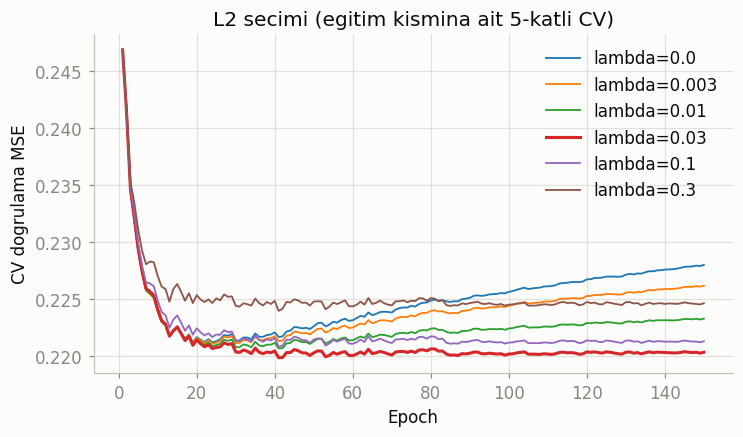

In [16]:
from sklearn.model_selection import StratifiedKFold

def cv_fold_features(images, labels, train_idx, val_idx, fold_seed):
    """Kat ici veri artirimi + merkezleme: yalnizca o katin egitim verisine fit."""
    if AUGMENT:
        img_tr, y_tr = augment_images(images[train_idx], labels[train_idx], seed=fold_seed)
    else:
        img_tr, y_tr = images[train_idx], labels[train_idx]
    x_tr_raw = extract_features(img_tr)
    mu_fold = x_tr_raw.mean(axis=1, keepdims=True)
    Xtr = x_tr_raw - mu_fold
    Xva = extract_features(images[val_idx]) - mu_fold
    Ytr = y_tr.reshape(1, -1).astype(np.float64)
    Yva = labels[val_idx].reshape(1, -1).astype(np.float64)
    return Xtr, Ytr, Xva, Yva


def cross_validate_l2(images, labels, lam_grid, n_splits=CV_FOLDS, n_epochs=CV_EPOCHS):
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)
    folds = []
    for k, (tr, va) in enumerate(skf.split(images, labels)):
        assert not set(tr).intersection(va)
        folds.append(cv_fold_features(images, labels, tr, va, RANDOM_STATE + k))
    rows, curves = [], {}
    for lam in lam_grid:
        mse_runs, acc_runs = [], []
        for k, (Xtr, Ytr, Xva, Yva) in enumerate(folds):
            res = model(Xtr, Ytr, Xva, Yva,
                        num_epochs=n_epochs, learning_rate=LEARNING_RATE,
                        patience=n_epochs + 1, min_delta=MIN_DELTA,
                        seed=RANDOM_STATE + k, verbose_every=0,
                        l2_lambda=lam, lr_decay=LR_DECAY)
            mse_runs.append(res['history']['val_mse'].to_numpy())
            acc_runs.append(res['history']['val_accuracy'].to_numpy())
        mean_mse = np.mean(mse_runs, axis=0)
        mean_acc = np.mean(acc_runs, axis=0)
        e = int(np.argmin(mean_mse))
        curves[lam] = mean_mse
        rows.append({'lambda': lam, 'best_epoch': e + 1,
                     'cv_val_mse': float(mean_mse[e]),
                     'cv_val_mse_std': float(np.std([r[e] for r in mse_runs])),
                     'cv_val_acc': float(mean_acc[e])})
        print(f'lambda={lam:<5} | en iyi epoch {e+1:3d} | '
              f'CV val MSE {mean_mse[e]:.5f} | CV val acc {mean_acc[e]:.3f}')
    return pd.DataFrame(rows), curves

# ESKI: X_train_raw, y_train_raw (dogrulama kumesini de CV'ye sokuyordu)
# YENI: X_cv_raw, y_cv (yalnizca orijinal egitim kismi)
t0 = time.perf_counter()
cv_df, cv_curves = cross_validate_l2(X_cv_raw, y_cv, L2_GRID)
best_row = cv_df.loc[cv_df['cv_val_mse'].idxmin()]
BEST_L2, CV_BEST_EPOCH = float(best_row['lambda']), int(best_row['best_epoch'])
print(f'\nSecilen L2 lambda = {BEST_L2} | secilen epoch = {CV_BEST_EPOCH} '
      f'| sure {time.perf_counter()-t0:.1f} s')
cv_df.to_csv(OUT_DIR / 'cv_l2_selection.csv', index=False)
if CV_BEST_EPOCH >= CV_EPOCHS - 2:
    print('UYARI: secilen epoch CV araliginin sonunda; CV_EPOCHS degerini artirin.')
if BEST_L2 >= max(L2_GRID):
    print('UYARI: secilen lambda izgaranin ucunda; izgarayi genisletin.')
fig, ax = plt.subplots(figsize=(7.5, 4))
for lam, curve in cv_curves.items():
    ax.plot(np.arange(1, len(curve) + 1), curve,
            label=f'lambda={lam}', lw=2 if lam == BEST_L2 else 1.2)
ax.set_xlabel('Epoch'); ax.set_ylabel('CV dogrulama MSE')
ax.set_title('L2 secimi (egitim kismina ait 5-katli CV)')
ax.legend()
save_fig('03b_cv_l2_secimi.png'); plt.show()

## Blok 16a. Karar eşiğini, eğitim kısmının out-of-fold tahminleriyle belirleme

CV'deki her doğrulama görüntüsü, **o görüntüyü eğitimde görmemiş modelden** tahmin alır. Veri artırımı ve ortalama çıkarma her katın kendi eğitim kısmından hesaplanır. Böylece 42 görüntülük ayrı doğrulama kümesi ve 50 görüntülük test kümesi eşik seçimine karışmaz.

Eşik, yalnızca `y_cv` etiketleri üzerindeki Balanced Accuracy ölçütüyle seçilir. Test başarısına göre eşik seçilmez.

In [17]:
def out_of_fold_probs(images, labels, lam, n_epochs):
    skf = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
    oof = np.zeros(len(labels), dtype=np.float64)
    for k, (tr, va) in enumerate(skf.split(images, labels)):
        Xtr, Ytr, Xva, Yva = cv_fold_features(images, labels, tr, va,
                                                RANDOM_STATE + k)
        res = model(Xtr, Ytr, Xva, Yva,
                    num_epochs=max(n_epochs, 5), learning_rate=LEARNING_RATE,
                    patience=max(n_epochs, 5) + 1, min_delta=MIN_DELTA,
                    seed=RANDOM_STATE + k, verbose_every=0,
                    l2_lambda=lam, lr_decay=LR_DECAY, restore_best=False)
        oof[va] = predict_proba(res['w'], res['b'], Xva)
    return oof

# ESKI: X_train_raw, y_train_raw -> YENI: X_cv_raw, y_cv
# (ayri dogrulama ve bagimsiz test verileri dahil degil)
oof_p = out_of_fold_probs(X_cv_raw, y_cv, BEST_L2, CV_BEST_EPOCH)
ths = np.linspace(0.1, 0.9, 81)
bal = np.array([balanced_accuracy_score(y_cv, oof_p >= t) for t in ths])
THRESHOLD = float(ths[np.flatnonzero(bal >= bal.max() - 1e-12)].mean())
print(f'OOF ROC-AUC: {roc_auc_score(y_cv, oof_p):.4f}')
print(f'OOF Balanced Acc @0.50: {balanced_accuracy_score(y_cv, oof_p >= 0.5):.4f} '
      f'| @{THRESHOLD:.2f}: {bal.max():.4f}')
print('Secilen karar esigi THRESHOLD =', round(THRESHOLD, 3))
pd.DataFrame({'threshold': ths, 'oof_balanced_accuracy': bal}).to_csv(
    OUT_DIR / 'threshold_oof.csv', index=False)

OOF ROC-AUC: 0.6291
OOF Balanced Acc @0.50: 0.5570 | @0.33: 0.6173
Secilen karar esigi THRESHOLD = 0.33


In [18]:
result = model(X_fit, Y_fit, X_val, Y_val,
               num_epochs=max(CV_BEST_EPOCH, 5), learning_rate=LEARNING_RATE,
               patience=max(CV_BEST_EPOCH, 5) + 1, min_delta=MIN_DELTA,
               seed=RANDOM_STATE, verbose_every=PRINT_EVERY,
               l2_lambda=BEST_L2, lr_decay=LR_DECAY, restore_best=False)
w, b, history = result['w'], result['b'], result['history']
print(f"\nSecilen epoch: {result['best_epoch']} | lambda: {BEST_L2} | son val MSE: {result['best_val_mse']:.6f}")
print(f"Egitim suresi (CPU): {result['train_seconds']:.2f} s")


Epoch   1/41 | train MSE 0.23362 | val MSE 0.23881 | train acc 0.347 | val acc 0.333
Epoch  25/41 | train MSE 0.17986 | val MSE 0.20715 | train acc 0.690 | val acc 0.667
Epoch  41/41 | train MSE 0.17548 | val MSE 0.20649 | train acc 0.705 | val acc 0.571

Secilen epoch: 41 | lambda: 0.03 | son val MSE: 0.206490
Egitim suresi (CPU): 1.85 s


## Blok 17. Öğrenme eğrileri: MSE ve doğruluk

Kaynak Notebook’taki **loss curve** yaklaşımını kullanıyoruz. Eğitim ve doğrulama eğrileri birlikte gösterildiği için aşırı öğrenme izlenebilir.

Grafik kaydedildi: outputs_module16_v5/04_ogrenme_egrileri.png


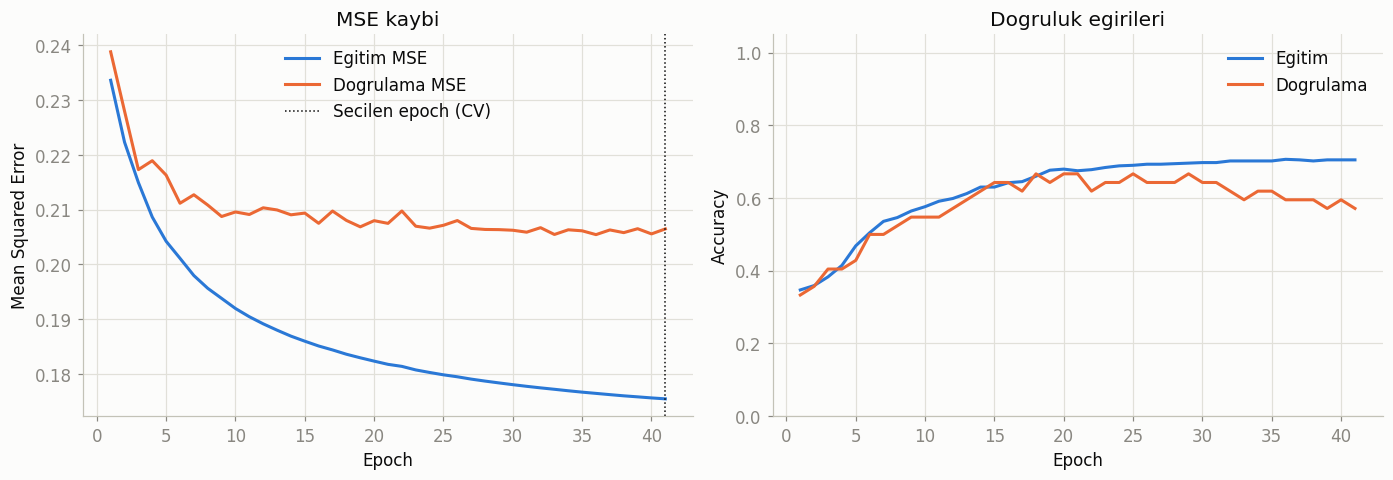

In [19]:
history.to_csv(OUT_DIR / 'training_history.csv', index=False)
fig, axes = plt.subplots(1, 2, figsize=(12.8, 4.5))
axes[0].plot(history['epoch'], history['train_mse'], color=C_TR, label='Egitim MSE')
axes[0].plot(history['epoch'], history['val_mse'], color=C_VA, label='Dogrulama MSE')
axes[0].axvline(result['best_epoch'], color=C_INK, ls=':', lw=1, label='Secilen epoch (CV)')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Mean Squared Error')
axes[0].set_title('MSE kaybi'); axes[0].legend()
axes[1].plot(history['epoch'], history['train_accuracy'], color=C_TR, label='Egitim')
axes[1].plot(history['epoch'], history['val_accuracy'], color=C_VA, label='Dogrulama')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Accuracy')
axes[1].set_ylim(0,1.05); axes[1].set_title('Dogruluk egirileri'); axes[1].legend()
plt.tight_layout(); save_fig('04_ogrenme_egrileri.png'); plt.show()

## Blok 18. Bağımsız doğrulama ve test sonuçları + karar eşiği karşılaştırması

Model bir kez eğitilir. Hem **sabit 0.50** hem de **eğitim CV'sinden seçilen eşik** ile aynı tahmin olasılıkları değerlendirilir. Karşılaştırma sadece raporlama içindir; en iyi test skoruna bakarak eşik yeniden seçilmez. Doğrulama kümesi CV'de kullanılmamıştır; test kümesi de tamamen ayrı tutulur.

In [20]:
p_fit, p_val, p_test = [predict_proba(w,b,X) for X in [X_fit, X_val, X_test]]
yhat_fit, yhat_val, yhat_test = [(p >= THRESHOLD).astype(int)
                                  for p in [p_fit,p_val,p_test]]

def evaluate_binary(y, p, threshold=None):
    threshold = THRESHOLD if threshold is None else threshold
    pred = (p >= threshold).astype(int)
    return {'Accuracy': accuracy_score(y,pred),
            'Balanced Accuracy': balanced_accuracy_score(y,pred),
            'Precision': precision_score(y,pred,zero_division=0),
            'Recall': recall_score(y,pred,zero_division=0),
            'F1': f1_score(y,pred,zero_division=0),
            'MSE': float(np.mean((p-y)**2)),
            'ROC-AUC': roc_auc_score(y,p) if len(np.unique(y)) == 2 else float('nan')}

metrics_df = pd.DataFrame({
    'Egitim': evaluate_binary(y_fit, p_fit),
    'Dogrulama': evaluate_binary(y_val, p_val),
    'Test': evaluate_binary(y_test, p_test),
}).T
print(metrics_df.round(4).to_string())
metrics_df.to_csv(OUT_DIR / 'metrics_train_validation_test.csv')
print('\nTest siniflandirma raporu:')
print(classification_report(y_test, yhat_test, target_names=['Kedi degil','Kedi'], zero_division=0))

# AYNI model, iki farkli esik. Test sonucuna bakip esik SECILMEZ.
threshold_comparison_rows = []
for split_name, target, probabilities in [
    ('Dogrulama', y_val, p_val), ('Test', y_test, p_test)]:
    for threshold_label, threshold_value in [('Sabit 0.50', 0.50),
                                             ('CV ile secilen', THRESHOLD)]:
        stats = evaluate_binary(target, probabilities, threshold=threshold_value)
        threshold_comparison_rows.append({
            'Veri': split_name, 'Esik_turu': threshold_label,
            'Esik_degeri': float(threshold_value), **stats})
threshold_comparison_df = pd.DataFrame(threshold_comparison_rows)
print('\nAyni model ile 0.50 ve CV esigi karsilastirmasi:')
print(threshold_comparison_df.round(4).to_string(index=False))
threshold_comparison_df.to_csv(OUT_DIR/'threshold_comparison.csv', index=False)
print('Not: Karar esigi yalnizca egitim CV verisinden secildi; '
      'test skorlarina gore degistirilmeyecek.')

           Accuracy  Balanced Accuracy  Precision  Recall      F1     MSE  ROC-AUC
Egitim       0.7051             0.7469     0.5467  0.8836  0.6755  0.1755   0.8386
Dogrulama    0.5714             0.5714     0.4000  0.5714  0.4706  0.2065   0.6888
Test         0.8400             0.7790     0.8205  0.9697  0.8889  0.2455   0.7683

Test siniflandirma raporu:
              precision    recall  f1-score   support

  Kedi degil       0.91      0.59      0.71        17
        Kedi       0.82      0.97      0.89        33

    accuracy                           0.84        50
   macro avg       0.86      0.78      0.80        50
weighted avg       0.85      0.84      0.83        50


Ayni model ile 0.50 ve CV esigi karsilastirmasi:
     Veri      Esik_turu  Esik_degeri  Accuracy  Balanced Accuracy  Precision  Recall     F1    MSE  ROC-AUC
Dogrulama     Sabit 0.50         0.50    0.6905             0.5714     0.6000  0.2143 0.3158 0.2065   0.6888
Dogrulama CV ile secilen         0.33    0.57

## Blok 19. Confusion matrix (karışıklık matrisi)

Gerçek ve tahmin edilen sınıfları ayrı ayrı gösteriyoruz: **TN / FP / FN / TP**.

Grafik kaydedildi: outputs_module16_v5/05_confusion_matrix.png


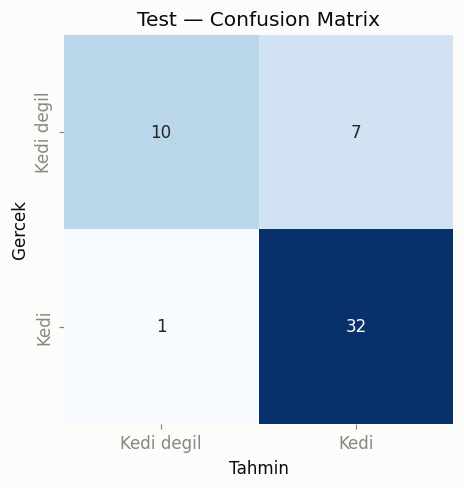

TN: 10, FP: 7, FN: 1, TP: 32


In [21]:
cm = confusion_matrix(y_test, yhat_test, labels=[0,1])
fig, ax = plt.subplots(figsize=(5.6, 4.6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, square=True,
            xticklabels=['Kedi degil','Kedi'],
            yticklabels=['Kedi degil','Kedi'], ax=ax)
ax.set_xlabel('Tahmin'); ax.set_ylabel('Gercek'); ax.set_title('Test — Confusion Matrix')
save_fig('05_confusion_matrix.png'); plt.show()
TN, FP, FN, TP = cm.ravel()
print(f'TN: {TN}, FP: {FP}, FN: {FN}, TP: {TP}')

## Blok 20. ROC eğrisi, AUC ve Precision–Recall eğrisi

Kaynak Notebook’taki ROC/AUC analizini burada ikili sınıflandırma için uyguluyoruz. ROC-AUC sınıf ayrımını, PR eğrisi pozitif sınıf başarısını gösterir.

Grafik kaydedildi: outputs_module16_v5/06_roc_pr.png


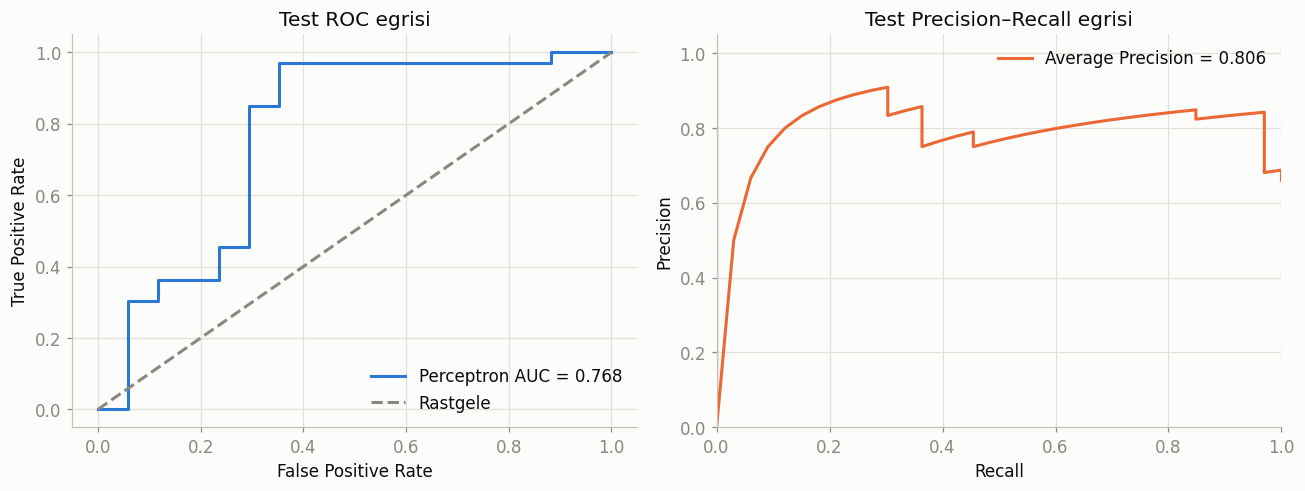

In [22]:
fpr, tpr, thresholds_roc = roc_curve(y_test, p_test)
auc_test = roc_auc_score(y_test, p_test)
precision_curve, recall_curve, thresholds_pr = precision_recall_curve(y_test, p_test)
ap_test = average_precision_score(y_test, p_test)
fig, axes = plt.subplots(1,2,figsize=(12,4.6))
axes[0].plot(fpr, tpr, color=C_TR, label=f'Perceptron AUC = {auc_test:.3f}')
axes[0].plot([0,1],[0,1],ls='--',color=C_MUTED,label='Rastgele')
axes[0].set_xlabel('False Positive Rate'); axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('Test ROC egrisi'); axes[0].legend(loc='lower right')
axes[1].plot(recall_curve,precision_curve,color=C_VA,label=f'Average Precision = {ap_test:.3f}')
axes[1].set_xlabel('Recall'); axes[1].set_ylabel('Precision')
axes[1].set_xlim(0,1); axes[1].set_ylim(0,1.05)
axes[1].set_title('Test Precision–Recall egrisi'); axes[1].legend()
plt.tight_layout(); save_fig('06_roc_pr.png'); plt.show()
pd.DataFrame({'fpr':fpr,'tpr':tpr,'threshold':thresholds_roc}).to_csv(OUT_DIR/'roc_points.csv',index=False)

## Blok 21. Sınıflar bazında Precision / Recall / F1 grafiği

İki sınıf için metrikleri ayrı gösteriyoruz; tüm örneklerde tek bir accuracy değeri yeterli olmayabilir.

Grafik kaydedildi: outputs_module16_v5/07_sinif_bazinda_metrikler.png


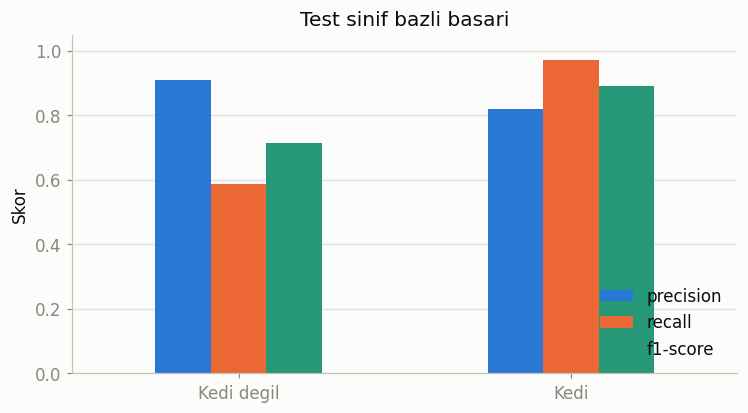

            precision  recall  f1-score
Kedi degil     0.9091  0.5882    0.7143
Kedi           0.8205  0.9697    0.8889


In [23]:
report = classification_report(y_test, yhat_test, labels=[0,1],
                               target_names=['Kedi degil','Kedi'],
                               output_dict=True, zero_division=0)
per_class = pd.DataFrame(report).T.loc[['Kedi degil','Kedi'],['precision','recall','f1-score']]
ax = per_class.plot.bar(figsize=(7.8,4),color=[C_TR,C_VA,C_TE],rot=0)
ax.set_ylim(0,1.05); ax.set_title('Test sinif bazli basari')
ax.set_ylabel('Skor'); ax.legend(loc='lower right')
ax.grid(axis='x',visible=False)
save_fig('07_sinif_bazinda_metrikler.png'); plt.show()
print(per_class.round(4).to_string())
per_class.to_csv(OUT_DIR/'per_class_metrics.csv')

## Blok 22. Eşik duyarlılığı (yalnızca ayrı doğrulama verisi)

Eşik seçimi önceki blokta yalnızca eğitim kısmına ait out-of-fold tahminlerden yapılmıştır. Bu grafik, **seçilmiş eşik çevresindeki metriklerin bağımsız doğrulama kümesinde nasıl değiştiğini** görselleştirir; yeni eşik seçmek için kullanılmaz.

Grafik kaydedildi: outputs_module16_v5/08_esik_analizi.png


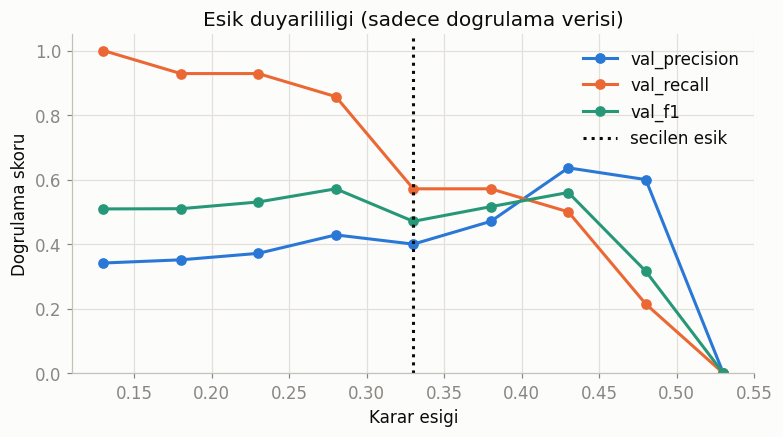

In [24]:
thresholds = np.linspace(max(0.05, THRESHOLD-0.2), min(0.95, THRESHOLD+0.2), 9)
threshold_rows = []
for t in thresholds:
    # Esik incelemesi dogrulama seti uzerinde yapilir: test leakage yok.
    pred = (p_val >= t).astype(int)
    threshold_rows.append({'threshold': float(t),
                           'val_precision': precision_score(y_val,pred,zero_division=0),
                           'val_recall': recall_score(y_val,pred,zero_division=0),
                           'val_f1': f1_score(y_val,pred,zero_division=0)})
thr = pd.DataFrame(threshold_rows)
fig, ax = plt.subplots(figsize=(8,4))
for col,c in [('val_precision',C_TR),('val_recall',C_VA),('val_f1',C_TE)]:
    ax.plot(thr['threshold'],thr[col],'o-',label=col,color=c)
ax.axvline(THRESHOLD,color=C_INK,ls=':',label='secilen esik')
ax.set_xlabel('Karar esigi'); ax.set_ylabel('Dogrulama skoru')
ax.set_title('Esik duyarililigi (sadece dogrulama verisi)')
ax.set_ylim(0,1.05); ax.legend()
save_fig('08_esik_analizi.png'); plt.show()
thr.to_csv(OUT_DIR/'threshold_analysis_validation.csv',index=False)

## Blok 23. Yanlış sınıflandırılan görüntüler

Kaynak Notebook’taki hatalı örnek görselleştirmesine paralel olarak test hatalarını, gerçek etiketlerini ve tahmin olasılıklarını birlikte çiziyoruz.

Hatali tahmin: 8 / 50
Grafik kaydedildi: outputs_module16_v5/09_yanlis_tahminler.png


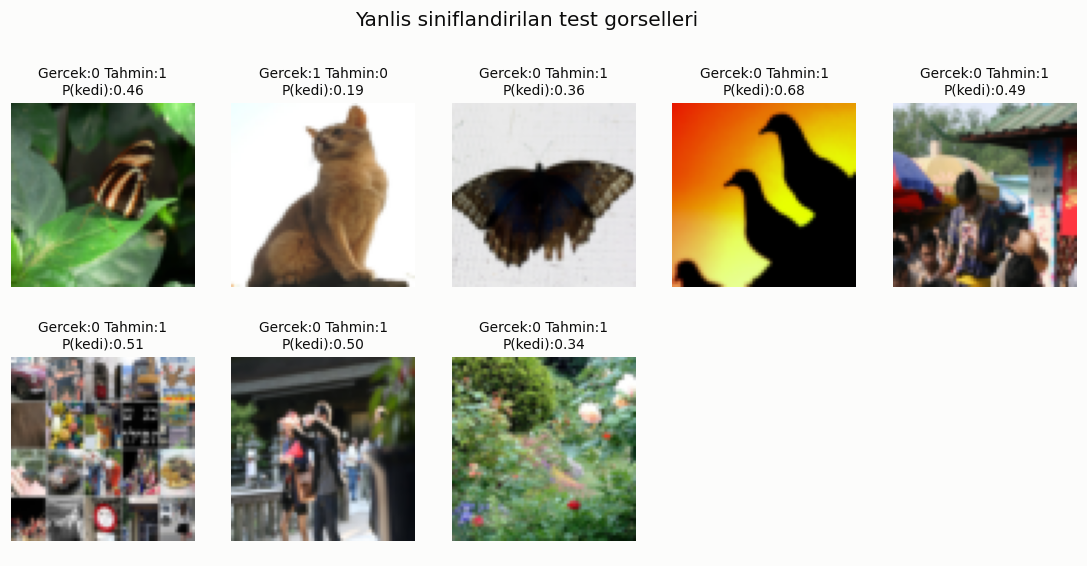

In [25]:
wrong = np.flatnonzero(yhat_test != y_test)
print('Hatali tahmin:',len(wrong),'/',len(y_test))
fig, axes = plt.subplots(2,5,figsize=(12.5,5.5))
for ax in axes.ravel(): ax.axis('off')
for ax,i in zip(axes.ravel(),wrong[:10]):
    ax.imshow(X_test_raw[i])
    ax.set_title(f'Gercek:{y_test[i]} Tahmin:{yhat_test[i]}\nP(kedi):{p_test[i]:.2f}',fontsize=9)
fig.suptitle('Yanlis siniflandirilan test gorselleri',y=1.01)
save_fig('09_yanlis_tahminler.png');plt.show()
misclassified_df = pd.DataFrame({'test_index':wrong, 'real':y_test[wrong],
                                 'pred':yhat_test[wrong], 'p_cat':p_test[wrong]})
misclassified_df.to_csv(OUT_DIR/'misclassified_samples.csv',index=False)

## Blok 24. Öğrenilmiş piksel ağırlıklarının görselleştirilmesi

Her RGB pikselinin eğitilen bağlantı ağırlığı vardır. Normalize edilmiş ağırlıkları 3 kanal için ayrı göstermek yorumlanabilirliği artırır; bir CNN filtre görselleştirmesi değildir.

Grafik kaydedildi: outputs_module16_v5/10_agirlik_haritalari.png


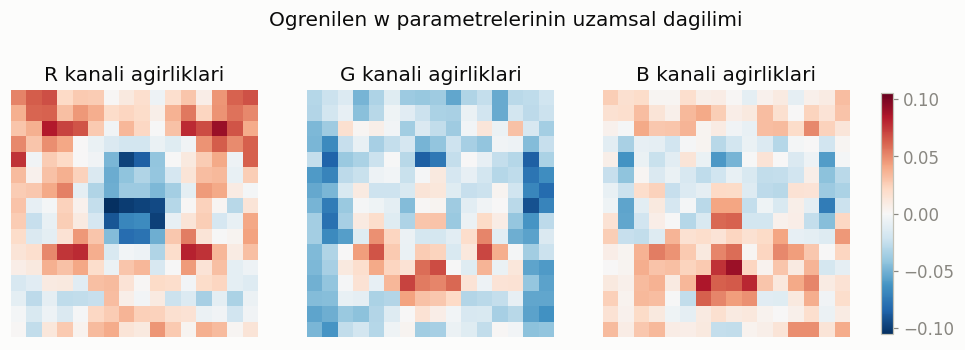

In [26]:
weights_img = w.reshape(FEAT_H, FEAT_W, IMG_C)
fig, axes = plt.subplots(1,3,figsize=(12,3.8))
vmax = max(1e-10,float(np.max(np.abs(weights_img))))
for ch,(name,ax) in enumerate(zip(['R','G','B'],axes)):
    im = ax.imshow(weights_img[:,:,ch],cmap='RdBu_r',vmin=-vmax,vmax=vmax)
    ax.set_title(f'{name} kanali agirliklari');ax.axis('off')
fig.colorbar(im,ax=list(axes),shrink=0.75,pad=0.03)
fig.suptitle('Ogrenilen w parametrelerinin uzamsal dagilimi')
save_fig('10_agirlik_haritalari.png');plt.show()

## Blok 25. Modelin kaydedilmesi ve tekrar yüklenmesi

Ağırlık, bias, görsel boyutu, eşik ve sınıf adlarını tek `pickle` dosyasına kaydediyoruz; model yeniden yüklendiğinde tahminlerin aynı olması gerekir.

In [27]:
model_path = OUT_DIR/'perceptron_sgd_mse.pkl'
model_data = {'w':w,'b':b,'img_shape':(IMG_H,IMG_W,IMG_C),
              'downsample':DOWNSAMPLE,'mu':MU,'l2_lambda':BEST_L2,
              'threshold':THRESHOLD, 'class_names':class_names,
              'config':result['hyperparameters'],'best_epoch':result['best_epoch']}
with open(model_path,'wb') as f:
    pickle.dump(model_data,f,protocol=pickle.HIGHEST_PROTOCOL)
with open(model_path,'rb') as f:
    loaded = pickle.load(f)
p_loaded = predict_proba(loaded['w'],loaded['b'],X_test)
assert np.allclose(p_loaded,p_test), 'Kayit / yukleme sonrasi tahmin farkli!'
print('Model dosyasi:',model_path,'| boyut (KB):',round(model_path.stat().st_size/1024,1))
print('Yukleme dogrulamasi: basarili')

Model dosyasi: outputs_module16_v5/perceptron_sgd_mse.pkl | boyut (KB): 12.4
Yukleme dogrulamasi: basarili


## Blok 26. Kendi fotoğrafınla kedi tanıma (Pillow)


Tum fotograflari birlikte secin. Adinda 'degil' veya 'değil' gecenler KEDI DEGIL sayilir.


Saving kedi.jpeg to kedi (2).jpeg
Saving kedi_degil_aslan.jpeg to kedi_degil_aslan (2).jpeg
Saving kedi_degil_aslan1.jpeg to kedi_degil_aslan1 (2).jpeg
Saving kedi_degil_kopek.jpeg to kedi_degil_kopek (2).jpeg
Saving kedi_degil_kus.jpeg to kedi_degil_kus (2).jpeg
Saving kedi_degil_kus1.jpeg to kedi_degil_kus1 (2).jpeg
Saving kedi_degil_penguen.jpeg to kedi_degil_penguen (2).jpeg
Saving kedi_degil_penguen1.jpeg to kedi_degil_penguen1 (2).jpeg
Saving kedi1.jpeg to kedi1 (2).jpeg
Saving kedi2.jpeg to kedi2 (2).jpeg
Saving kedi3.jpeg to kedi3 (2).jpeg
Saving kedi4.jpg to kedi4 (2).jpg
Saving kedi5.jpeg to kedi5 (2).jpeg
Saving kedi6.webp to kedi6 (2).webp
Saving kedi7.jpeg to kedi7 (2).jpeg
Saving kedi8.jpeg to kedi8 (2).jpeg
                       dosya     gercek  p_kedi     tahmin  dogru
               kedi (2).jpeg       Kedi   0.314 Kedi degil      0
              kedi1 (2).jpeg       Kedi   0.270 Kedi degil      0
              kedi2 (2).jpeg       Kedi   0.337       Kedi      1
    

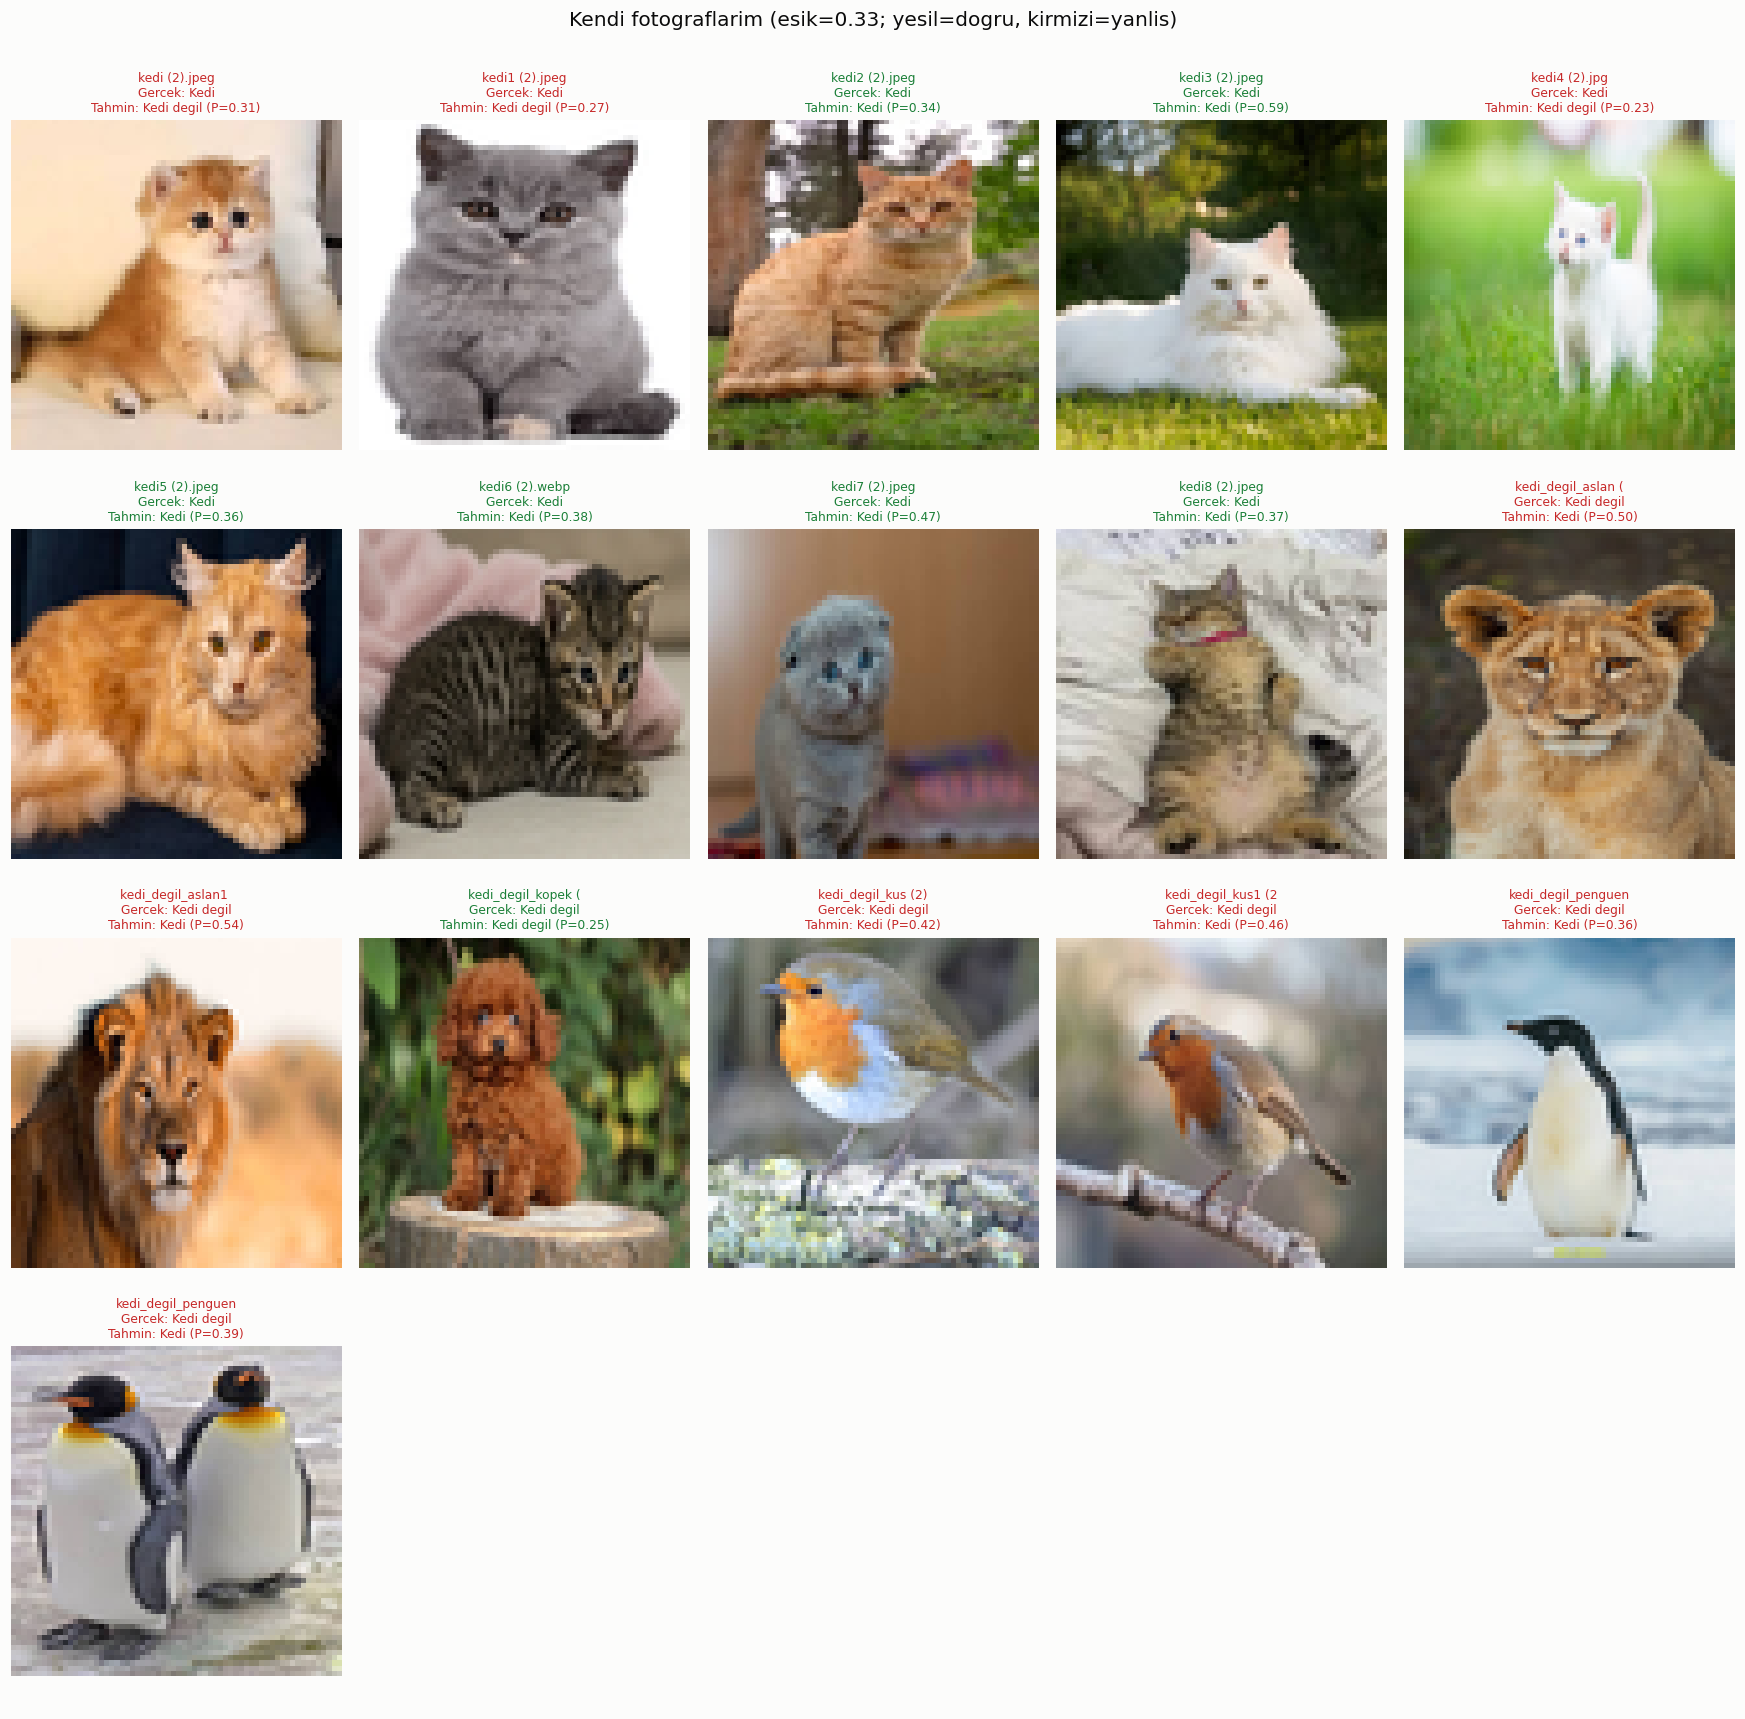

In [28]:
AUTO_UPLOAD = True
OWN_IMAGE_PATHS = []     # Colab disi: ['kedi1.jpg', 'kedi_degil_kus.jpg']

if AUTO_UPLOAD:
    try:
        from google.colab import files
        print("Tum fotograflari birlikte secin. Adinda 'degil' veya 'değil' gecenler KEDI DEGIL sayilir.")
        OWN_IMAGE_PATHS = list(files.upload().keys())
    except ImportError:
        print('Colab degil: OWN_IMAGE_PATHS listesine dosya yollarini yazin.')

def prepare_own_image(path):
    with Image.open(path) as im:
        im = ImageOps.exif_transpose(im).convert('RGB').resize((IMG_W, IMG_H), Image.Resampling.LANCZOS)
    small_u8 = np.asarray(im, dtype=np.uint8)
    return small_u8, preprocess_images(small_u8[None])

paths = sorted(p for p in OWN_IMAGE_PATHS if Path(p).is_file())
assert paths, 'Fotograf bulunamadi.'
rows, shown_imgs = [], []
for p in paths:
    name = Path(p).name
    true = 0 if ('degil' in name.lower() or 'değil' in name.lower()) else 1
    img, X_one = prepare_own_image(p)
    prob = float(predict_proba(w, b, X_one)[0])
    pred = int(prob >= THRESHOLD)
    rows.append({'dosya': name, 'gercek': 'Kedi' if true else 'Kedi degil',
                 'p_kedi': prob, 'tahmin': 'Kedi' if pred else 'Kedi degil', 'dogru': int(pred == true)})
    shown_imgs.append(img)

own_df = pd.DataFrame(rows)
print(own_df.round(3).to_string(index=False))
y_true = (own_df['gercek'] == 'Kedi').astype(int); y_pred = (own_df['tahmin'] == 'Kedi').astype(int)
print(f"\nDogruluk: {own_df['dogru'].mean():.2f} ({own_df['dogru'].sum()}/{len(own_df)}) | "
      f"kedi recall: {y_pred[y_true==1].mean():.2f} | kedi-degil recall: {1-y_pred[y_true==0].mean():.2f}")
if y_true.nunique() == 2:
    print('Kendi fotograflarda ROC-AUC:', round(roc_auc_score(y_true, own_df['p_kedi']), 3))

cols = min(5, len(paths)); r = int(np.ceil(len(paths) / cols))
fig, axes = plt.subplots(r, cols, figsize=(3.2*cols, 3.9*r), squeeze=False)
for ax in axes.ravel(): ax.axis('off')
for ax, img, (_, row) in zip(axes.ravel(), shown_imgs, own_df.iterrows()):
    ax.imshow(img)
    ax.set_title(f"{row['dosya'][:18]}\nGercek: {row['gercek']}\nTahmin: {row['tahmin']} (P={row['p_kedi']:.2f})",
                 fontsize=8, color=('#1a7f37' if row['dogru'] else '#c62828'))
fig.suptitle(f'Kendi fotograflarim (esik={THRESHOLD:.2f}; yesil=dogru, kirmizi=yanlis)', y=1.0)
plt.tight_layout(); save_fig('11_kendi_gorseller.png'); plt.show()
own_df.to_csv(OUT_DIR / 'kendi_gorsel_tahminleri.csv', index=False)

## Blok 27. Modelin sınırlılıkları ve deney yorumu

Küçük bir görüntü veri setinde tek nöronlu doğrusal modelin neden sınırlı olduğunu, doğrulama setinin rolünü ve matematiksel olarak tam olarak neyi yaptığımızı kayıt altına alıyoruz.

In [29]:
interpretations = [
    f"Veri: {N_FIT_ORIG} orijinal egitim (artirimla {len(y_fit)}) + {len(y_val)} dogrulama + {len(y_test)} bagimsiz test gorseli.",
    f"Girdi {IMG_H}x{IMG_W} -> {FEAT_H}x{FEAT_W} kucultuldu ({N_FEATURES} ozellik), egitim ortalamasi cikarildi.",
    f"Veri artirimi (cevirme + donme) yalnizca egitim bolumune uygulandi; L2 lambda = {BEST_L2} ve epoch = {CV_BEST_EPOCH} yalnizca egitim kisminin 5-katli CV verisiyle secildi.",
    f"Sigmoid + MSE (+L2 weight decay) kullanildi; optimizasyon her ornekten sonra gercek SGD (eta={LEARNING_RATE}).",
    f"Secilen epoch = {result['best_epoch']}; dogrulama MSE = {result['best_val_mse']:.5f}.",
    f"Bagimsiz test Accuracy = {metrics_df.loc['Test','Accuracy']:.4f}; F1 = {metrics_df.loc['Test','F1']:.4f}; ROC-AUC = {metrics_df.loc['Test','ROC-AUC']:.4f}.",
    'Dogrusal tek-noronlu model uzamsal kenar/doku iliskilerini CNN gibi ogrenemez.',
    'MSE + sigmoid secimi PDF geregi yapilmistir; BCE cogu ikili problemde daha yaygin olsa da burada kullanilmadi.',
    'Kucuk test kumesi nedeniyle sonuclar yuksek varyans gosterebilir; testten hiperparametre secilmedi.',
    f'Esik karsilastirmasi ayni modelde 0.50 ve CV-secili {THRESHOLD:.3f} icin raporlandi; val/test esik seciminde kullanilmadi.',
    'Yanlis siniflamalar veri, goruntu ve model kapasitesi sinirlarindan kaynaklanabilir.',
]
print('\n'.join(f'- {s}' for s in interpretations))
(OUT_DIR/'yorumlar.txt').write_text('\n'.join(interpretations),encoding='utf-8')

- Veri: 167 orijinal egitim (artirimla 668) + 42 dogrulama + 50 bagimsiz test gorseli.
- Girdi 64x64 -> 16x16 kucultuldu (768 ozellik), egitim ortalamasi cikarildi.
- Veri artirimi (cevirme + donme) yalnizca egitim bolumune uygulandi; L2 lambda = 0.03 ve epoch = 41 yalnizca egitim kisminin 5-katli CV verisiyle secildi.
- Sigmoid + MSE (+L2 weight decay) kullanildi; optimizasyon her ornekten sonra gercek SGD (eta=0.002).
- Secilen epoch = 41; dogrulama MSE = 0.20649.
- Bagimsiz test Accuracy = 0.8400; F1 = 0.8889; ROC-AUC = 0.7683.
- Dogrusal tek-noronlu model uzamsal kenar/doku iliskilerini CNN gibi ogrenemez.
- MSE + sigmoid secimi PDF geregi yapilmistir; BCE cogu ikili problemde daha yaygin olsa da burada kullanilmadi.
- Kucuk test kumesi nedeniyle sonuclar yuksek varyans gosterebilir; testten hiperparametre secilmedi.
- Esik karsilastirmasi ayni modelde 0.50 ve CV-secili 0.330 icin raporlandi; val/test esik seciminde kullanilmadi.
- Yanlis siniflamalar veri, goruntu ve model kapasit

1012

## Blok 28. Sonuç özeti, CSV/JSON dosyaları ve ZIP dışa aktarımı

Önceki Notebook’taki son blokla aynı şekilde ölçümleri ve tüm grafikleri bir klasörde toplayıp ZIP dosyası oluşturuyoruz.

In [30]:
final = {
    'dataset': DATASET_SLUG,
    'train_samples':int(N_FIT_ORIG), 'train_samples_augmented':int(len(y_fit)),
    'downsample':int(DOWNSAMPLE), 'augmentation':bool(AUGMENT),
    'l2_lambda':float(BEST_L2), 'decision_threshold':float(THRESHOLD), 'threshold_baseline':0.5, 'cv_selected_epoch':int(CV_BEST_EPOCH), 'validation_samples':int(len(y_val)),
    'test_samples':int(len(y_test)), 'n_features':int(N_FEATURES),
    'model':'single sigmoid neuron / perceptron', 'loss':'MSE + L2 (weight decay)',
    'optimizer':'true SGD (single example per update)',
    'learning_rate':float(LEARNING_RATE),
    'epochs_trained':int(len(history)), 'best_epoch':int(result['best_epoch']),
    'best_validation_mse':float(result['best_val_mse']),
    'train_seconds':round(float(result['train_seconds']),3),
    'test_accuracy':round(float(metrics_df.loc['Test','Accuracy']),5),
    'test_precision':round(float(metrics_df.loc['Test','Precision']),5),
    'test_recall':round(float(metrics_df.loc['Test','Recall']),5),
    'test_f1':round(float(metrics_df.loc['Test','F1']),5),
    'test_mse':round(float(metrics_df.loc['Test','MSE']),5),
    'test_roc_auc':round(float(metrics_df.loc['Test','ROC-AUC']),5),
    'test_average_precision':round(float(ap_test),5),
    'confusion_matrix':cm.tolist(), 'random_state':int(RANDOM_STATE),
}
with open(OUT_DIR/'final_results.json','w',encoding='utf-8') as f:
    json.dump(final,f,ensure_ascii=False,indent=2)
pd.DataFrame({'true_label':y_test,'pred_label':yhat_test,
              'p_cat':p_test}).to_csv(OUT_DIR/'test_predictions.csv',index=False)
zip_path = shutil.make_archive('Module16_Perceptron_Sonuclar','zip',OUT_DIR)
print(json.dumps(final,ensure_ascii=False,indent=2))
print('\nCikti klasoru:',OUT_DIR.resolve())
print('Dosyalar:')
for f in sorted(OUT_DIR.iterdir()):print('  ',f.name)
print('ZIP dosyasi:',zip_path)

{
  "dataset": "muhammeddalkran/catvnoncat",
  "train_samples": 167,
  "train_samples_augmented": 668,
  "downsample": 4,
  "augmentation": true,
  "l2_lambda": 0.03,
  "decision_threshold": 0.33,
  "threshold_baseline": 0.5,
  "cv_selected_epoch": 41,
  "validation_samples": 42,
  "test_samples": 50,
  "n_features": 768,
  "model": "single sigmoid neuron / perceptron",
  "loss": "MSE + L2 (weight decay)",
  "optimizer": "true SGD (single example per update)",
  "learning_rate": 0.002,
  "epochs_trained": 41,
  "best_epoch": 41,
  "best_validation_mse": 0.20649028574046152,
  "train_seconds": 1.845,
  "test_accuracy": 0.84,
  "test_precision": 0.82051,
  "test_recall": 0.9697,
  "test_f1": 0.88889,
  "test_mse": 0.24546,
  "test_roc_auc": 0.76827,
  "test_average_precision": 0.80574,
  "confusion_matrix": [
    [
      10,
      7
    ],
    [
      1,
      32
    ]
  ],
  "random_state": 42
}

Cikti klasoru: /content/outputs_module16_v5
Dosyalar:
   01_ornek_gorseller.png
   02_sinif

---
### Teslim kontrol listesi

- [x] Perceptron / tek sigmoid nöron **sıfırdan NumPy ile** yazıldı.
- [x] Ağırlık (`w`) ve bias (`b`) başlatıldı.
- [x] Forward, MSE, backward ve **tek örneklik SGD** fonksiyonları ayrı kuruldu.
- [x] Bütün parçalar **`model()`** fonksiyonunda birleştirildi.
- [x] PDF'deki **Cat vs Non-Cat H5** veri setinin eğitim/test ayrımı korundu.
- [x] Doğrulama verisi eğitimden ayrıldı; epoch ve L2 katsayısı 5-katlı CV ile seçildi.
- [x] Aşırı öğrenmeye karşı: görüntü küçültme, merkezleme, veri artırımı (yalnızca eğitim) ve L2 (loss hâlâ MSE).
- [x] Accuracy, Precision, Recall, F1, ROC-AUC, PR ve confusion matrix hesaplandı.
- [x] Sigmoid, loss, doğruluk ve hatalı tahmin grafikleri oluşturuldu.
- [x] Model kaydedildi / yeniden yüklendi; kendi fotoğrafınla tahmin özelliği eklendi.
- [x] CSV, JSON, PKL, PNG ve ZIP çıktıları hazırlandı.

**Kaynak veri:** https://www.kaggle.com/datasets/muhammeddalkran/catvnoncat  
**Ödev:** *DLI Accelerated Data Science Teaching Kit — Module 16 Lab: Binary Classification with Perceptron*.